In [3]:
import pandas as pd 
import numpy as np 
import matplotlib as plt 
import seaborn as sns 


In [5]:
df = pd.read_csv('steam-200k.csv')
df.head(10)

,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
0,151603712,The Elder Scrolls V Skyrim,play,273.0,0
1,151603712,Fallout 4,purchase,1.0,0
2,151603712,Fallout 4,play,87.0,0
3,151603712,Spore,purchase,1.0,0
4,151603712,Spore,play,14.9,0
5,151603712,Fallout New Vegas,purchase,1.0,0
6,151603712,Fallout New Vegas,play,12.1,0
7,151603712,Left 4 Dead 2,purchase,1.0,0
8,151603712,Left 4 Dead 2,play,8.9,0
9,151603712,HuniePop,purchase,1.0,0


In [3]:
df.describe()

,151603712,1.0,0
count,1.999990e+05,199999.000000,199999.0
mean,1.036556e+08,17.874468,0.0
std,7.208084e+07,138.057292,0.0
min,5.250000e+03,0.100000,0.0
25%,4.738420e+07,1.000000,0.0
50%,8.691201e+07,1.000000,0.0
75%,1.542309e+08,1.300000,0.0
max,3.099031e+08,11754.000000,0.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199999 entries, 0 to 199998
Data columns (total 5 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   151603712                   199999 non-null  int64  
 1   The Elder Scrolls V Skyrim  199999 non-null  object 
 2   purchase                    199999 non-null  object 
 3   1.0                         199999 non-null  float64
 4   0                           199999 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB


In [5]:
df.shape

(199999, 5)

In [6]:
for columna in df.select_dtypes(include='object').columns:
    print(f"\n--- {columna} ---")
    print(df[columna].isnull().sum())


--- The Elder Scrolls V Skyrim ---
0

--- purchase ---
0


In [8]:
df.duplicated().sum()

np.int64(707)

In [6]:
#analizamos los duplicados 

df[df.duplicated(keep=False)].head(10)

,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1786,11373749,Sid Meier's Civilization IV,purchase,1.0,0
1967,11373749,Sid Meier's Civilization IV,purchase,1.0,0
1968,11373749,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0,0
1969,11373749,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0,0
1970,11373749,Sid Meier's Civilization IV Warlords,purchase,1.0,0
1971,11373749,Sid Meier's Civilization IV Warlords,purchase,1.0,0
2722,56038151,Grand Theft Auto San Andreas,purchase,1.0,0
2723,56038151,Grand Theft Auto San Andreas,purchase,1.0,0
2724,56038151,Grand Theft Auto Vice City,purchase,1.0,0
2725,56038151,Grand Theft Auto Vice City,purchase,1.0,0


In [7]:
# se eliminan las 707 filas que son iguales 

df_limpio = df.drop_duplicates().copy()

print("Filas originales:", len(df))
print("Filas limpias:", len(df_limpio))
print("Duplicados restantes:", df_limpio.duplicated().sum())

Filas originales: 199999
Filas limpias: 199292
Duplicados restantes: 0


In [10]:
df_limpio.columns

Index(['151603712', 'The Elder Scrolls V Skyrim', 'purchase', '1.0', '0'], dtype='object')

In [9]:
#cambiamos los nomnres para mejor comprensión 

df_limpio.columns = [
    "usuario",
    "juego",
    "comportamiento",
    "valor",
    "extra"
]

df_limpio.head()

,usuario,juego,comportamiento,valor,extra
0,151603712,The Elder Scrolls V Skyrim,play,273.0,0
1,151603712,Fallout 4,purchase,1.0,0
2,151603712,Fallout 4,play,87.0,0
3,151603712,Spore,purchase,1.0,0
4,151603712,Spore,play,14.9,0


In [10]:
df_limpio["comportamiento"].value_counts()

comportamiento
purchase    128803
play         70489
Name: count, dtype: int64

In [11]:
# Df después de la limpieza
print("Dimensiones:", df_limpio.shape)

print("\nTipos de datos:")
print(df_limpio.dtypes)

print("\nValores nulos:")
print(df_limpio.isnull().sum())

print("\nUsuarios únicos:", df_limpio["usuario"].nunique())

print("Videojuegos únicos:", df_limpio["juego"].nunique())

print("\nEstadísticas descriptivas:")
display(df_limpio.describe(include="all"))

Dimensiones: (199292, 5)

Tipos de datos:
usuario             int64
juego              object
comportamiento     object
valor             float64
extra               int64
dtype: object

Valores nulos:
usuario           0
juego             0
comportamiento    0
valor             0
extra             0
dtype: int64

Usuarios únicos: 12393
Videojuegos únicos: 5155

Estadísticas descriptivas:


,usuario,juego,comportamiento,valor,extra
count,1.992920e+05,199292,199292,199292.000000,199292.0
unique,NaN,5155,2,NaN,NaN
top,NaN,Dota 2,purchase,NaN,NaN
freq,NaN,9682,128803,NaN,NaN
mean,1.037179e+08,NaN,NaN,17.934332,0.0
std,7.212058e+07,NaN,NaN,138.298294,0.0
min,5.250000e+03,NaN,NaN,0.100000,0.0
25%,4.738430e+07,NaN,NaN,1.000000,0.0
50%,8.691201e+07,NaN,NaN,1.000000,0.0
75%,1.542309e+08,NaN,NaN,1.400000,0.0


In [14]:
# Registros de compras
compras = df_limpio[
    df_limpio["comportamiento"] == "purchase"
]

# Registros de juego
juegos = df_limpio[
    df_limpio["comportamiento"] == "play"
]

print("Registros de compra:", len(compras))
print("Registros de juego:", len(juegos))

Registros de compra: 128803
Registros de juego: 70489


In [15]:
# Cantidad de juegos comprados por usuario
juegos_comprados = (
    compras.groupby("usuario")["juego"]
    .nunique()
    .rename("juegos_comprados")
)

# Cantidad de juegos en los que registra actividad
juegos_jugados = (
    juegos.groupby("usuario")["juego"]
    .nunique()
    .rename("juegos_jugados")
)

# Total de horas registradas por usuario
horas_totales = (
    juegos.groupby("usuario")["valor"]
    .sum()
    .rename("horas_totales")
)

# Unir las variables en una tabla
df_usuarios = pd.concat(
    [juegos_comprados, juegos_jugados, horas_totales],
    axis=1
).fillna(0)

df_usuarios.head()

,juegos_comprados,juegos_jugados,horas_totales
usuario,,,
5250,21,6.0,225.5
76767,36,20.0,1227.0
86540,82,15.0,255.0
103360,10,0.0,0.0
144736,8,1.0,0.1


In [16]:
horas_totales = (
    juegos.groupby("usuario")["valor"]
    .sum()
    .rename("horas_totales")
)

horas_totales.head()

usuario
5250       225.5
76767     1227.0
86540      255.0
144736       0.1
181212       2.2
Name: horas_totales, dtype: float64

In [17]:
df_usuarios = pd.concat(
    [juegos_comprados, juegos_jugados, horas_totales],
    axis=1
).fillna(0)

df_usuarios.head()

,juegos_comprados,juegos_jugados,horas_totales
usuario,,,
5250,21,6.0,225.5
76767,36,20.0,1227.0
86540,82,15.0,255.0
103360,10,0.0,0.0
144736,8,1.0,0.1


In [18]:
print("Dimensiones:", df_usuarios.shape)
print("\nValores nulos:")
print(df_usuarios.isnull().sum())

df_usuarios.describe()

Dimensiones: (12393, 3)

Valores nulos:
juegos_comprados    0
juegos_jugados      0
horas_totales       0
dtype: int64


,juegos_comprados,juegos_jugados,horas_totales
count,12393.000000,12393.000000,12393.000000
mean,10.393206,5.686839,278.009021
std,35.635824,17.078531,760.270618
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,1.300000
50%,2.000000,1.000000,13.500000
75%,6.000000,3.000000,155.600000
max,1068.000000,498.000000,11754.000000


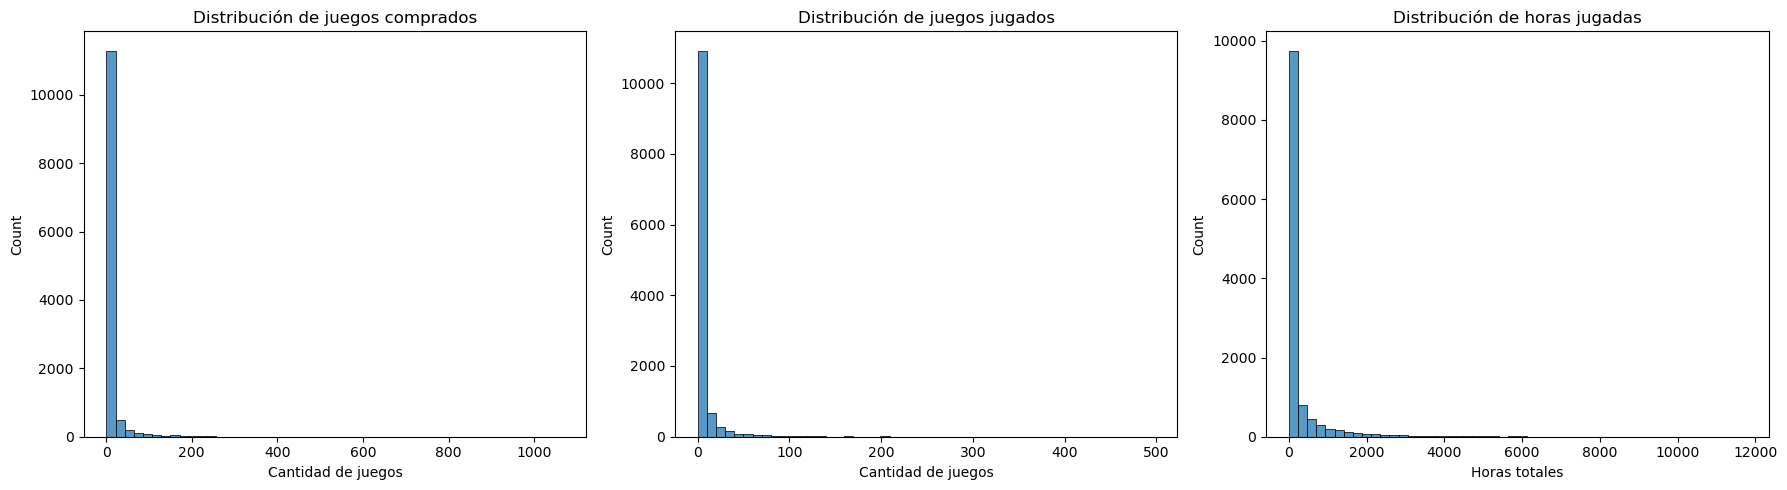

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=df_usuarios, x="juegos_comprados", bins=50, ax=axes[0])
axes[0].set_title("Distribución de juegos comprados")
axes[0].set_xlabel("Cantidad de juegos")

sns.histplot(data=df_usuarios, x="juegos_jugados", bins=50, ax=axes[1])
axes[1].set_title("Distribución de juegos jugados")
axes[1].set_xlabel("Cantidad de juegos")

sns.histplot(data=df_usuarios, x="horas_totales", bins=50, ax=axes[2])
axes[2].set_title("Distribución de horas jugadas")
axes[2].set_xlabel("Horas totales")

plt.tight_layout()
plt.show()


In [20]:

# Crear una copia para conservar los datos originales
df_transformado = df_usuarios.copy()

# Aplicar transformación logarítmica
columnas = [
    "juegos_comprados",
    "juegos_jugados",
    "horas_totales"
]

df_transformado[columnas] = np.log1p(
    df_transformado[columnas]
)

df_transformado.head()


,juegos_comprados,juegos_jugados,horas_totales
usuario,,,
5250,3.091042,1.945910,5.422745
76767,3.610918,3.044522,7.113142
86540,4.418841,2.772589,5.545177
103360,2.397895,0.000000,0.000000
144736,2.197225,0.693147,0.095310


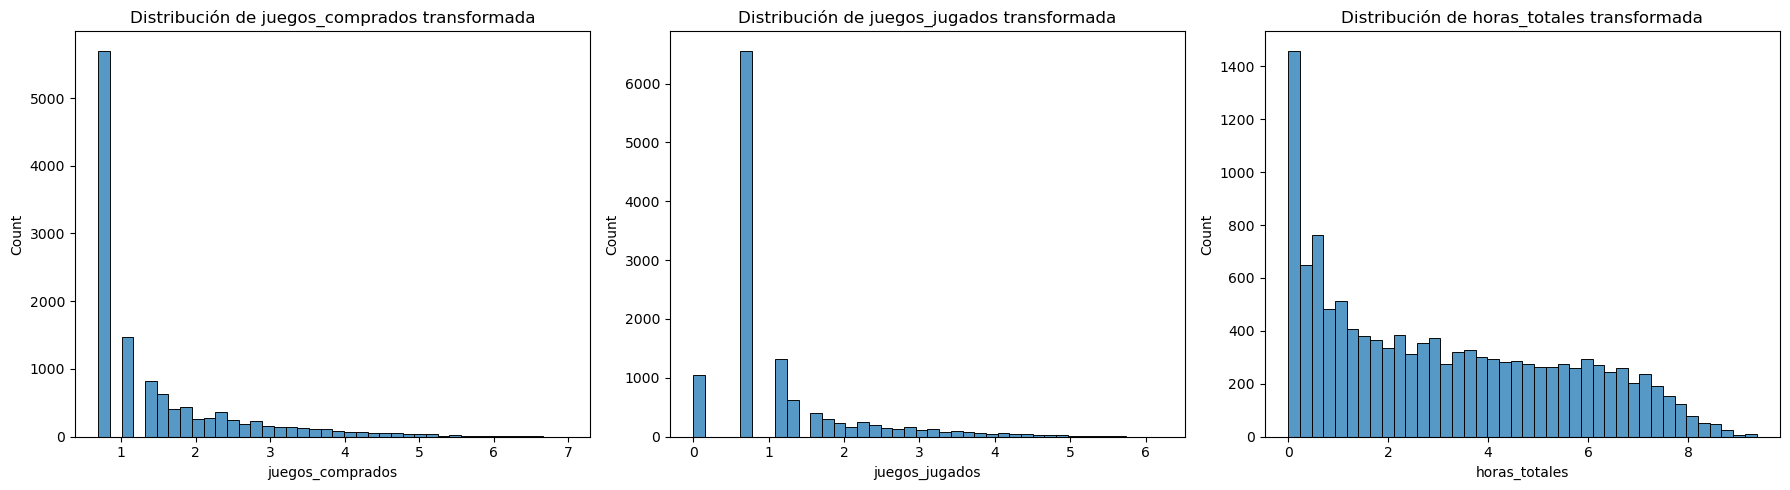

In [21]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, columna in enumerate(columnas):
    sns.histplot(df_transformado[columna], bins=40, ax=axes[i])
    axes[i].set_title(f"Distribución de {columna} transformada")

plt.tight_layout()
plt.show()


In [22]:

from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()

# Estandarizamos las variables transformadas 
X_escalado = scaler.fit_transform(df_transformado[columnas])

# Convertir el resultado en DataFrame para visualizarlo
df_escalado = pd.DataFrame(
    X_escalado,
    columns=columnas,
    index=df_transformado.index
)

df_escalado.head()


,juegos_comprados,juegos_jugados,horas_totales
usuario,,,
5250,1.516963,0.843982,0.967274
76767,2.006483,2.010694,1.661647
86540,2.767231,1.721904,1.017566
103360,0.864288,-1.222550,-1.260254
144736,0.675334,-0.486437,-1.221103


In [23]:

print("Medias:")
print(df_escalado.mean().round(2))

print("\nDesviaciones estándar:")
print(df_escalado.std().round(2))


Medias:
juegos_comprados    0.0
juegos_jugados     -0.0
horas_totales      -0.0
dtype: float64

Desviaciones estándar:
juegos_comprados    1.0
juegos_jugados      1.0
horas_totales       1.0
dtype: float64


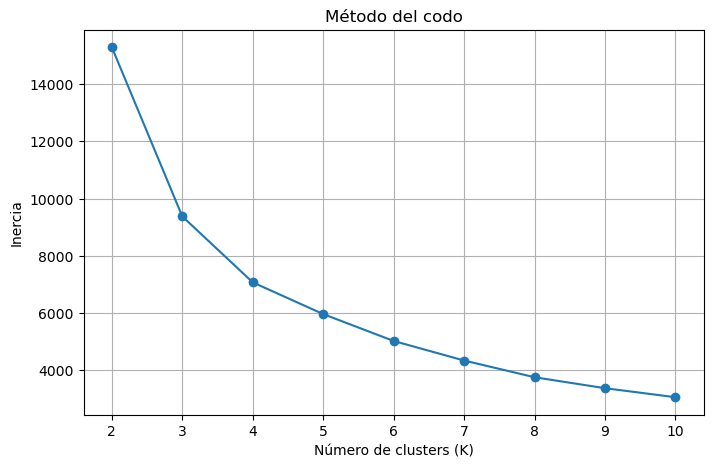

In [24]:

from sklearn.cluster import KMeans

inercias = []
valores_k = range(2, 11)

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    modelo.fit(df_escalado)
    inercias.append(modelo.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(valores_k, inercias, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()


In [25]:

from sklearn.metrics import silhouette_score

resultados_silhouette = []

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(df_escalado)

    puntuacion = silhouette_score(
        df_escalado,
        etiquetas
    )

    resultados_silhouette.append(puntuacion)

    print(f"K = {k}: Silhouette = {puntuacion:.4f}")


K = 2: Silhouette = 0.5805
K = 3: Silhouette = 0.4687
K = 4: Silhouette = 0.4360
K = 5: Silhouette = 0.4339
K = 6: Silhouette = 0.3835
K = 7: Silhouette = 0.3742
K = 8: Silhouette = 0.4131
K = 9: Silhouette = 0.4236
K = 10: Silhouette = 0.4172


In [26]:

modelo_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df_usuarios["cluster"] = modelo_kmeans.fit_predict(df_escalado)

df_usuarios["cluster"].value_counts().sort_index()



cluster
0    4061
1    1692
2    6640
Name: count, dtype: int64

In [27]:

perfil_clusters = (
    df_usuarios
    .groupby("cluster")[
        ["juegos_comprados", "juegos_jugados", "horas_totales"]
    ]
    .agg(["mean", "median", "count"])
    .round(2)
)

display(perfil_clusters)


juegos_comprados              juegos_jugados               \
                    mean median count           mean median count   
cluster                                                             
0                   4.63    3.0  4061           2.70    2.0  4061   
1                  57.94   30.0  1692          31.43   18.0  1692   
2                   1.80    1.0  6640           0.95    1.0  6640   

        horas_totales                
                 mean  median count  
cluster                              
0              327.97  104.00  4061  
1             1231.57  745.65  1692  
2                4.46    1.50  6640

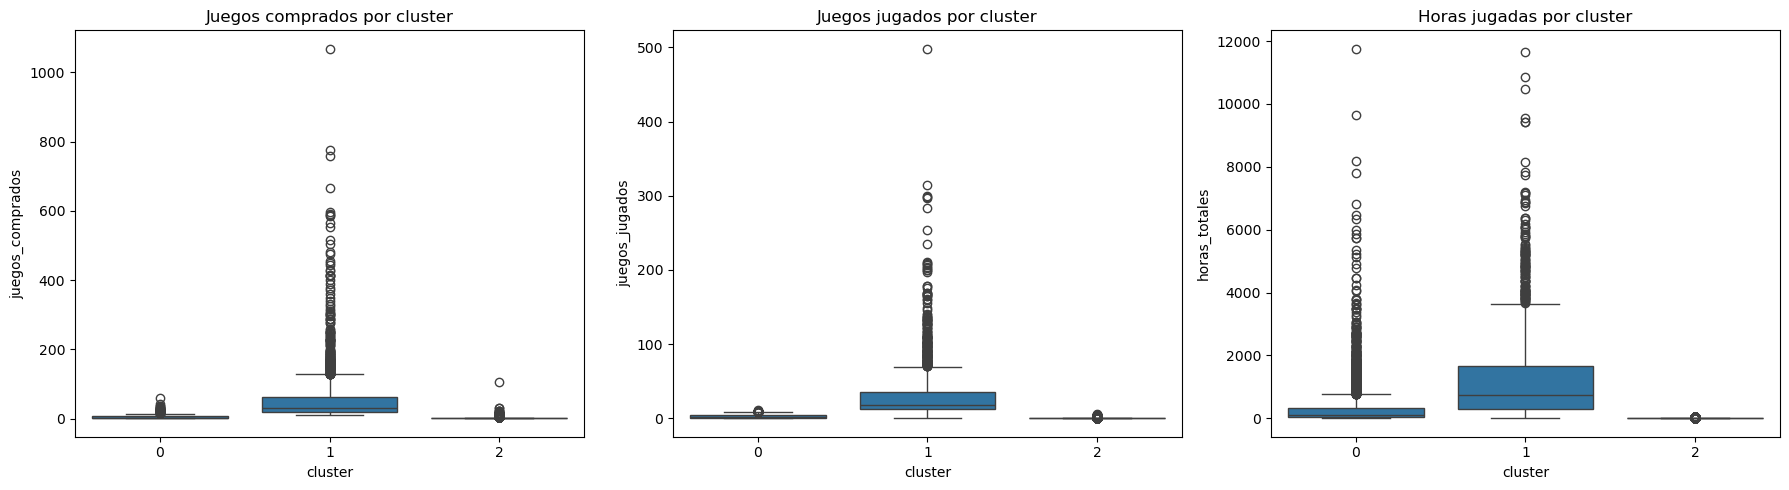

In [28]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df_usuarios, x="cluster", y="juegos_comprados", ax=axes[0])
axes[0].set_title("Juegos comprados por cluster")

sns.boxplot(data=df_usuarios, x="cluster", y="juegos_jugados", ax=axes[1])
axes[1].set_title("Juegos jugados por cluster")

sns.boxplot(data=df_usuarios, x="cluster", y="horas_totales", ax=axes[2])
axes[2].set_title("Horas jugadas por cluster")

plt.tight_layout()
plt.show()


In [16]:

from IPython.display import HTML, display

display(HTML("""
<div style="font-family: Arial, sans-serif; color: #333;
            line-height: 1.7; max-width: 950px; margin: auto;">

    <h1 style="color: #1e3a5f;">
        🎮 Recomendaciones de negocio
    </h1>

    <p>
        A partir de la segmentación realizada con K-Means, se identificaron
        tres grupos de usuarios de Steam con diferentes niveles de compra y
        actividad de juego. Teniendo en cuenta estas características, se
        proponen estrategias de marketing y fidelización para cada segmento.
    </p>

    <h2 style="color: #1e3a5f;">6.1. Estrategias de marketing por segmento</h2>

    <h3 style="color: #239b65;">
        🟢 Cluster 0: Jugadores habituales
    </h3>

    <p>
        Este grupo está compuesto por 4.061 usuarios, equivalentes
        aproximadamente al 32,8 % del total analizado. Presenta un promedio
        de 4,63 juegos comprados, 2,70 juegos jugados y 327,97 horas acumuladas.
    </p>

    <p><strong>Estrategia de marketing:</strong> incentivar la continuidad
    del juego y motivar la compra de nuevos videojuegos mediante
    recomendaciones personalizadas.</p>

    <p><strong>Promociones propuestas:</strong></p>
    <ul>
        <li>Descuentos en videojuegos similares a los que ya han jugado.</li>
        <li>Ofertas especiales por la compra de un segundo videojuego.</li>
        <li>Recompensas por completar determinados objetivos de actividad.</li>
    </ul>

    <p>
        El objetivo es incentivar a los usuarios para que aumenten sus horas
        de juego y sus compras.
    </p>

    <h3 style="color: #c28a00;">
        🟡 Cluster 1: Coleccionistas y jugadores intensivos
    </h3>

    <p>
        Este grupo está compuesto por 1.692 usuarios, aproximadamente el
        13,7 % del total. Registra los promedios más altos, con 57,94 juegos
        comprados, 31,43 juegos jugados y 1.231,57 horas acumuladas.
    </p>

    <p><strong>Estrategia de marketing:</strong> implementar acciones de
    fidelización y ofrecer experiencias personalizadas que reconozcan su
    alto nivel de participación y adquisición de videojuegos.</p>

    <p><strong>Promociones propuestas:</strong></p>
    <ul>
        <li>Acceso anticipado a demos de videojuegos nuevos.</li>
        <li>Descuentos por compras múltiples.</li>
        <li>Recompensas por antigüedad o participación.</li>
    </ul>

    <p>
        Este segmento debería ser prioritario para las campañas de fidelización,
        debido a su alta actividad histórica y a la cantidad de juegos que adquiere.
    </p>

    <h3 style="color: #df5252;">
        🔴 Cluster 2: Usuarios de baja actividad
    </h3>

    <p>
        Es el grupo más grande, con 6.640 usuarios, aproximadamente el 53,6 %
        del total. Presenta un promedio de 1,80 juegos comprados, 0,95 juegos
        jugados y 4,46 horas acumuladas.
    </p>

    <p><strong>Estrategia de marketing:</strong> mejorar la exploración de la
    plataforma y evaluar acciones de activación que permitan aumentar la
    participación de los usuarios.</p>

    <p><strong>Promociones propuestas:</strong></p>
    <ul>
        <li>Descuentos en videojuegos económicos o gratuitos.</li>
        <li>Ofertas de bienvenida para usuarios con poca actividad.</li>
        <li>Recomendaciones de juegos populares o fáciles de comenzar.</li>
        <li>Campañas de reactivación para usuarios que lleven un tiempo sin jugar.</li>
    </ul>

    <p>
        Antes de invertir en campañas para todo el segmento, convendría
        distinguir entre usuarios nuevos, ocasionales y aquellos que han
        abandonado la plataforma. El dataset actual no permite diferenciarlos
        con certeza.
    </p>

    <h2 style="color: #1e3a5f;">
        6.2. Usuarios prioritarios para campañas de fidelización
    </h2>

    <p>
        Se priorizaría inicialmente al <strong>cluster 1</strong>, conformado
        por los coleccionistas y jugadores intensivos, debido a sus elevados
        niveles históricos de adquisición y actividad.
    </p>

    <p>
        En segundo lugar, se trabajaría con el <strong>cluster 0</strong>,
        mediante promociones destinadas a incrementar la frecuencia de compra
        y ampliar la variedad de videojuegos utilizados.
    </p>

    <p>
        Finalmente, para el <strong>cluster 2</strong>, se implementarían
        campañas de activación de bajo costo, evaluando sus resultados antes
        de ampliar la inversión.
    </p>

    <h2 style="color: #1e3a5f;">
        6.3. Información adicional útil para mejorar la segmentación
    </h2>

    <p>
        Para construir segmentos más precisos y diseñar estrategias de
        marketing mejor orientadas, sería útil incorporar las siguientes variables:
    </p>

    <ul>
        <li><strong>Fecha de última conexión:</strong> permitiría identificar
        usuarios activos, inactivos y posiblemente abandonados.</li>

        <li><strong>Frecuencia de juego:</strong> ayudaría a diferenciar a
        quienes juegan diariamente de quienes se conectan ocasionalmente.</li>

        <li><strong>Gasto total y gasto por videojuego:</strong> permitiría
        estimar el valor económico de cada usuario.</li>

        <li><strong>Fecha de compra y antigüedad de la cuenta:</strong>
        facilitaría identificar usuarios nuevos y analizar cambios en su comportamiento.</li>

        <li><strong>Géneros preferidos:</strong> permitiría ofrecer
        recomendaciones y promociones personalizadas.</li>

        <li><strong>Respuesta a campañas anteriores:</strong> ayudaría a
        identificar qué descuentos y comunicaciones producen mejores resultados.</li>

        <li><strong>Uso de descuentos:</strong> permitiría analizar la
        sensibilidad de los usuarios a los precios.</li>
    </ul>

    <p style="margin-top: 30px; padding-top: 15px;
              border-top: 1px solid #ddd; color: #66758a; font-size: 13px;">
        Proyecto de análisis de datos · Segmentación de usuarios de Steam mediante K-Means
    </p>

</div>
"""))
